In [10]:
RUN_A = ("2026-10-12_18-11-06", "No preprocessing")    # (folder name, label for charts)
RUN_B = ("2026-10-12_19-18-28", "Preprocessing")

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUNS = Path.cwd() / "runs"

def load_run(name: str, label: str) -> tuple[pd.DataFrame, str]:
    """Read one run's scores.csv and tag every row with a label."""
    run_dir = RUNS / name
    df = pd.read_csv(run_dir / "scores.csv").dropna(subset=["cer", "wer"])
    df["run"] = label
    seed = (run_dir / "seed.txt").read_text().strip()
    print(f"{label}: {name}  seed={seed}  rows={len(df)}")
    return df, seed

[d.name for d in sorted(RUNS.iterdir()) if (d / "scores.csv").exists()]

['2026-10-12_18-11-06', '2026-10-12_19-18-28']

In [12]:
df_a, seed_a = load_run(*RUN_A)
df_b, seed_b = load_run(*RUN_B)
la, lb = RUN_A[1], RUN_B[1]

No preprocessing: 2026-10-12_18-11-06  seed=42  rows=70
Preprocessing: 2026-10-12_19-18-28  seed=42  rows=70


In [13]:
if seed_a != seed_b:
    print(f"⚠ different seeds ({seed_a} vs {seed_b}): the runs tested different pages")

keys = ["model", "image"]
common = df_a[keys].merge(df_b[keys], on=keys)
df = pd.concat([df_a, df_b]).merge(common, on=keys)
print(f"Comparing {common['model'].nunique()} models on {len(common)} shared (model, image) pairs")

Comparing 7 models on 70 shared (model, image) pairs


In [14]:
summary = (df.groupby(["model", "run"])
             .agg(avg_cer=("cer", "mean"), avg_wer=("wer", "mean"),
                  max_cer=("cer", "max"),  max_wer=("wer", "max"))
             .reset_index())
worst = df.loc[df.groupby(["model", "run"])["cer"].idxmax(), ["model", "run", "image"]]
summary = summary.merge(worst.rename(columns={"image": "worst_image"}), on=["model", "run"])
summary

,model,run,avg_cer,avg_wer,max_cer,max_wer,worst_image
0,google/gemma-3-12b,No preprocessing,0.036220,0.113459,0.143382,0.411765,img001_0956-6
1,google/gemma-3-12b,Preprocessing,0.042735,0.129103,0.202206,0.529412,img001_0956-6
2,google/gemma-3-4b,No preprocessing,0.057192,0.146341,0.150735,0.352941,img001_0956-6
3,google/gemma-3-4b,Preprocessing,0.061368,0.169785,0.180147,0.490196,img001_0956-6
4,google/gemma-4-12b,No preprocessing,0.026194,0.060331,0.066421,0.156863,img008_0178-6
5,google/gemma-4-12b,Preprocessing,0.026718,0.077540,0.095588,0.274510,img001_0956-6
6,google/gemma-4-e2b,No preprocessing,0.039290,0.099677,0.150735,0.333333,img001_0956-6
7,google/gemma-4-e2b,Preprocessing,0.047337,0.129368,0.209559,0.490196,img001_0956-6
8,google/gemma-4-e4b,No preprocessing,0.038573,0.125087,0.132353,0.392157,img001_0956-6
9,google/gemma-4-e4b,Preprocessing,0.037826,0.113632,0.150735,0.372549,img001_0956-6


In [15]:
wide = summary.pivot(index="model", columns="run", values=["avg_cer", "avg_wer"])
delta = pd.DataFrame({
    f"CER {la}": wide["avg_cer"][la], f"CER {lb}": wide["avg_cer"][lb],
    "CER change": wide["avg_cer"][lb] - wide["avg_cer"][la],
    f"WER {la}": wide["avg_wer"][la], f"WER {lb}": wide["avg_wer"][lb],
    "WER change": wide["avg_wer"][lb] - wide["avg_wer"][la],
}).sort_values(f"CER {lb}")
(delta * 100).round(2)

,CER No preprocessing,CER Preprocessing,CER change,WER No preprocessing,WER Preprocessing,WER change
model,,,,,,
google/gemma-4-12b,2.62,2.67,0.05,6.03,7.75,1.72
qwen/qwen3.5-9b,2.34,3.64,1.30,6.09,8.94,2.85
google/gemma-4-e4b,3.86,3.78,-0.07,12.51,11.36,-1.15
google/gemma-3-12b,3.62,4.27,0.65,11.35,12.91,1.56
google/gemma-4-e2b,3.93,4.73,0.80,9.97,12.94,2.97
mistralai/ministral-3-3b,6.45,5.34,-1.11,16.28,15.34,-0.94
google/gemma-3-4b,5.72,6.14,0.42,14.63,16.98,2.34


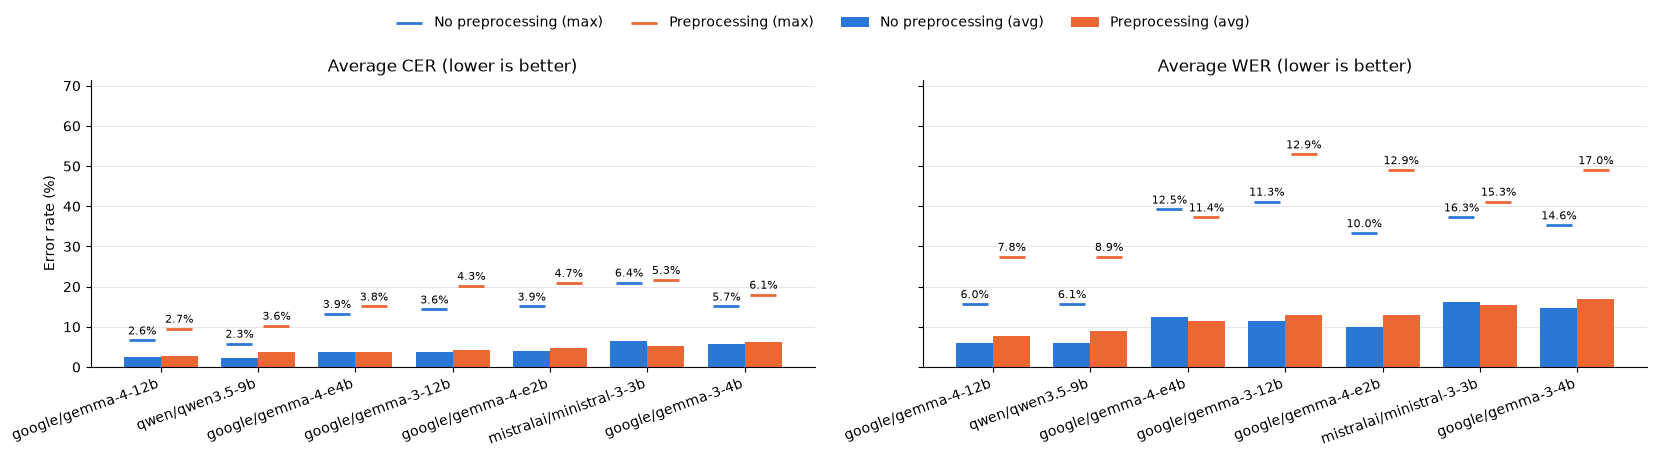

In [16]:
COLORS = {la: "#2a78d6", lb: "#eb6834"}
models = delta.index.tolist()
x, w = range(len(models)), 0.38

fig, axes = plt.subplots(1, 2, figsize=(max(9, 2.4 * len(models)), 4.5), sharey=True)
for ax, metric in [(axes[0], "cer"), (axes[1], "wer")]:
    for label, offset in [(la, -w/2), (lb, w/2)]:
        s = summary[summary["run"] == label].set_index("model").loc[models]
        xs = [i + offset for i in x]
        ax.bar(xs, s[f"avg_{metric}"] * 100, w, color=COLORS[label], label=f"{label} (avg)")
        ax.scatter(xs, s[f"max_{metric}"] * 100, marker="_", s=350, linewidths=2,
                   color=COLORS[label], label=f"{label} (max)")
        for xi, avg, mx in zip(xs, s[f"avg_{metric}"], s[f"max_{metric}"]):
            ax.text(xi, mx * 100 + 0.8, f"{avg:.1%}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"Average {metric.upper()} (lower is better)")
    ax.set_xticks(list(x)); ax.set_xticklabels(models, rotation=20, ha="right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

axes[0].set_ylabel("Error rate (%)")
axes[0].set_ylim(0, summary[["max_cer", "max_wer"]].max().max() * 100 * 1.35)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()